## 1. E-commerce Customer Analytics Using Machine Learning

**Project Overview**

This project analyzes e-commerce customer data using four analytical techniques:

1. Regression — predict customer spending.
2. Classification — predict customer churn.
3. Clustering — segment customers based on their behavior.
4. Association Rule Mining — discover product purchasing patterns.

**Business Objectives**

- Understand customer spending behavior.
- Identify customers who may have churned.
- Discover meaningful customer segments.
- Identify products frequently purchased together.
- Generate actionable business insights.

**Dataset**

File: "ecommerce_multitask_dataset.csv"

**Important Assumption**

For this project, we assume:

- "ChurnStatus = 1": Customer has churned.
- "ChurnStatus = 0": Customer is active.

**Tools and Libraries**

Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, and Mlxtend.

**Methodology**

Dataset inspection → Data cleaning → Exploratory data analysis → Preprocessing → Regression → Classification → Clustering → Association Rule Mining → Results and conclusions.


## 2. Import libraries

In [1]:
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

In [2]:
# Regression

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error

from sklearn.metrics import mean_squared_error

from sklearn.metrics import r2_score

In [3]:
# Classification

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score

from sklearn.metrics import classification_report

from sklearn.metrics import confusion_matrix

In [4]:
# Clustering

from sklearn.cluster import KMeans

In [5]:
# Association

from mlxtend.preprocessing import TransactionEncoder

from mlxtend.frequent_patterns import apriori,association_rules

# 3. Load dataset

In [6]:
df=pd.read_csv(r"C:\Users\Administrator\Documents\Project ML\ecommerce-customer-analytics\ecommerce_multitask_dataset.csv")

In [7]:
df.head()

,CustomerID,Age,AnnualIncome,SpendingScore,TotalPurchases,ChurnStatus,TotalSpent,ItemsBought
0,CUST_1000,56,125186,58,13,0,16247.405882,Charger
1,CUST_1001,69,54674,67,49,0,21973.364975,"T-Shirt,Shoes,Phone"
2,CUST_1002,46,55854,56,41,0,19399.861629,Smartwatch
3,CUST_1003,32,66271,40,17,0,12791.643911,"Smartwatch,Cover,Phone,Mouse"
4,CUST_1004,60,93688,98,9,0,21285.349780,"Cover,Keyboard,Charger,Phone"


# 4. Basic EDA

In [8]:
# 4.1 Columns list
df.columns

Index(['CustomerID', 'Age', 'AnnualIncome', 'SpendingScore', 'TotalPurchases',
       'ChurnStatus', 'TotalSpent', 'ItemsBought'],
      dtype='object')

In [9]:
# 4.2 Check datatypes of columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   CustomerID      1000 non-null   object 
 1   Age             1000 non-null   int64  
 2   AnnualIncome    1000 non-null   int64  
 3   SpendingScore   1000 non-null   int64  
 4   TotalPurchases  1000 non-null   int64  
 5   ChurnStatus     1000 non-null   int64  
 6   TotalSpent      1000 non-null   float64
 7   ItemsBought     1000 non-null   object 
dtypes: float64(1), int64(5), object(2)
memory usage: 62.6+ KB


In [10]:
# 4.3 Statistical summary of dataset
df.describe()

,Age,AnnualIncome,SpendingScore,TotalPurchases,ChurnStatus,TotalSpent
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,43.81900,84905.976000,49.064000,25.575000,0.022000,16757.179209
std,14.99103,38430.889006,28.857281,14.178696,0.146757,5366.730282
min,18.00000,20060.000000,1.000000,1.000000,0.000000,3189.210861
25%,31.00000,51945.500000,24.000000,14.000000,0.000000,13011.698063
50%,44.00000,84699.000000,47.000000,25.000000,0.000000,16517.367868
75%,56.00000,117858.000000,75.000000,38.000000,0.000000,20672.234808
max,69.00000,149972.000000,99.000000,49.000000,1.000000,31138.539140


In [11]:
# 4.4 Check null values
df.isnull().sum()

CustomerID        0
Age               0
AnnualIncome      0
SpendingScore     0
TotalPurchases    0
ChurnStatus       0
TotalSpent        0
ItemsBought       0
dtype: int64

In [12]:
# 4.5 Check duplicate records
df.duplicated().sum()

np.int64(0)

**Basic EDA Summary**

The dataset was checked for missing values and duplicate records. No missing values or duplicate rows were detected in the initial inspection. 

No records were removed without a clear justification. Further preprocessing will be performed according to the requirements of each machine learning technique.

# **5. Data Visualization**

# 5.1 Analyze the age distribution
A histogram helps us understand how customer ages are distributed. It shows which age ranges occur most frequently in the dataset.

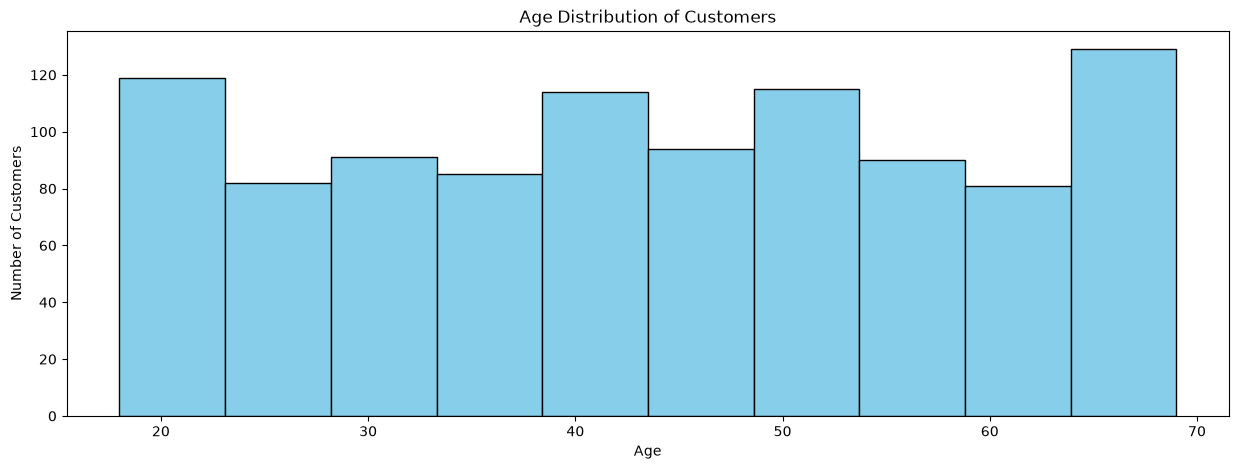

In [13]:
plt.figure(figsize=(15, 5))

plt.hist(df["Age"], bins=10, edgecolor="black", color="skyblue")

plt.title("Age Distribution of Customers")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

**Report:-**

The age distribution histogram shows that customers belong to different age groups, ranging from 18 to 69 years. The dataset includes both younger and older customers, providing a diverse customer base for analysis. Age can be investigated as a potential feature for customer segmentation and spending prediction.

# 5.2 Analyze annual income

This histogram shows the distribution of annual income among customers and helps us identify common income ranges and potentially unusual values.

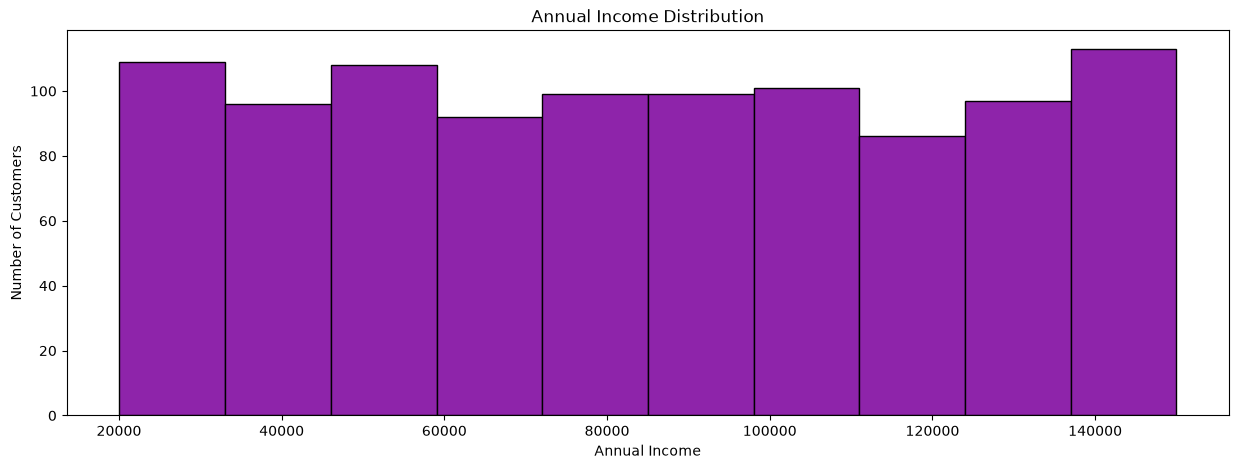

In [14]:
plt.figure(figsize=(15, 5))

plt.hist(df["AnnualIncome"], bins=10, edgecolor="black", color="#8E24AA")

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income")
plt.ylabel("Number of Customers")

plt.show()

**Report:-**

The annual income histogram shows a wide range of customer income levels, from approximately 20,060 to 149,972. The observations are spread across different income ranges, allowing us to study customer spending behavior across income groups. Annual income may be useful for customer segmentation and predicting total spending.

# 5.3 Analyze customer spending scores

This histogram helps us understand whether customer spending scores are concentrated in particular range.

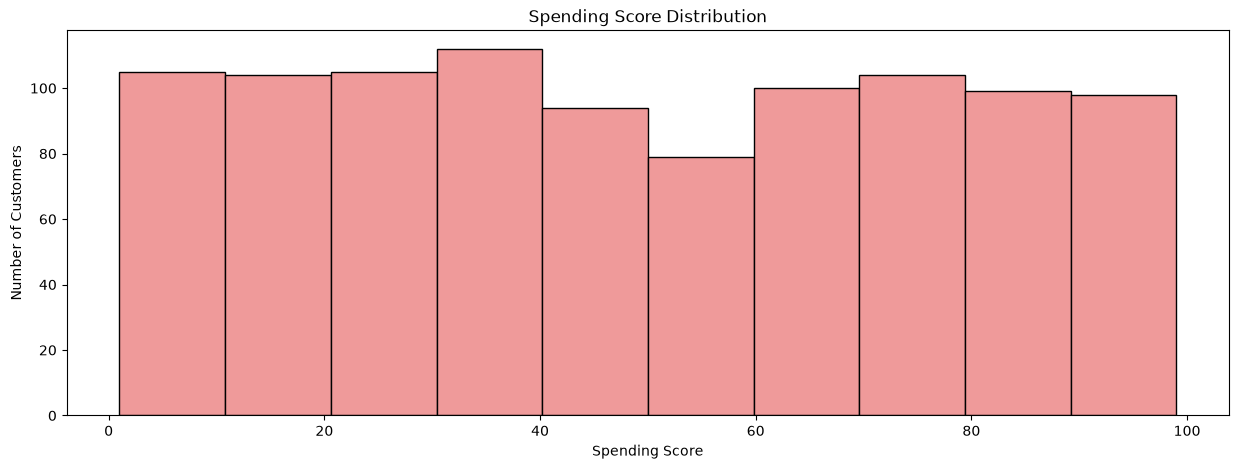

In [15]:
plt.figure(figsize=(15, 5))

plt.hist(df["SpendingScore"], bins=10, edgecolor="black",color="#EF9A9A")

plt.title("Spending Score Distribution")
plt.xlabel("Spending Score")
plt.ylabel("Number of Customers")

plt.show()

**Report:-**

The spending score ranges from 1 to 99, covering customers with different spending behaviors. The distribution includes low, medium, and high spending scores. This feature is particularly relevant for customer segmentation and shows a strong positive correlation with TotalSpent in the correlation analysis.

# 5.4 Analyze churn status

A count plot displays the number of customers in each churn category. This is important because the classification model may perform poorly if one category contains far fewer records than the other.

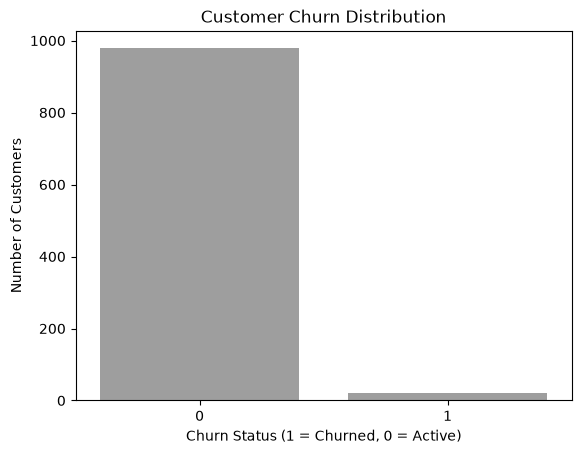

In [16]:
sns.countplot(x="ChurnStatus", data=df, color="#9E9E9E")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status (1 = Churned, 0 = Active)")
plt.ylabel("Number of Customers")

plt.show()

**Report:-**

The dataset contains 1,000 customers, of whom 978 have ChurnStatus = 0 and 22 have ChurnStatus = 1. Assuming that 1 represents churned customers and 0 represents active customers, approximately 2.2% of customers have churned.

# 5.5 Analyze the realtionship between income and spending

We will analyze do customers with higher incomes also have higher spending scores, or are the points spread across different combinations?

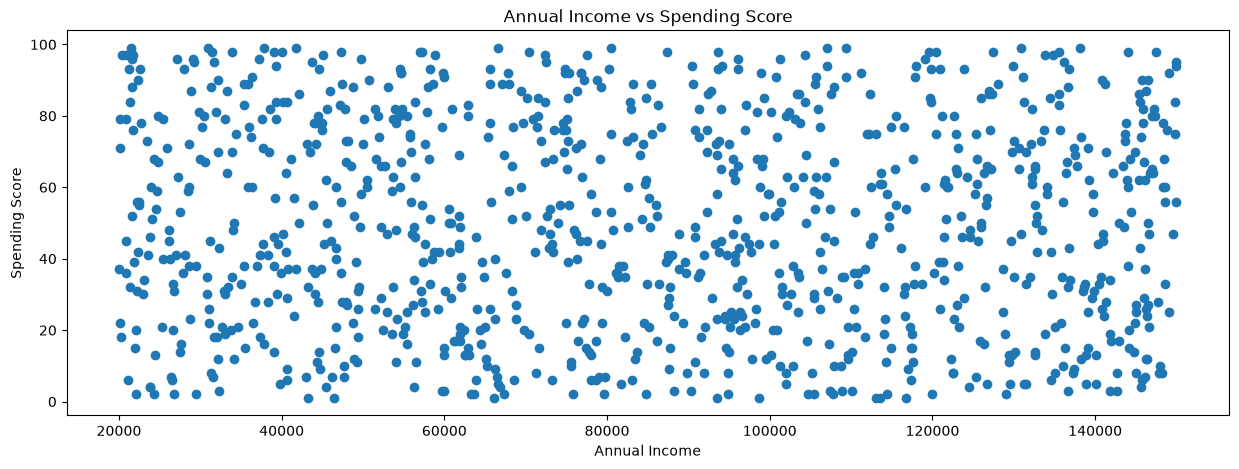

In [17]:

plt.figure(figsize=(15, 5))

plt.scatter(df["AnnualIncome"], df["SpendingScore"])

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")

plt.show()

**Report:-**

The scatter plot helps examine the relationship between annual income and spending score. The correlation coefficient is approximately -0.034, indicating almost no linear relationship between these two variables in this dataset. Customers with higher annual income do not necessarily have higher spending scores.

# 5.6 Correlation Analysis
Correlation analysis helps us understand how numerical variables are related. A positive correlation indicates that two variables tend to increase together, while a negative correlation indicates that one tends to decrease as the other increases.


In [18]:
correlation=df.corr(numeric_only=True)

print(correlation)

                     Age  AnnualIncome  SpendingScore  TotalPurchases  \
Age             1.000000      0.016999       0.015088       -0.000132   
AnnualIncome    0.016999      1.000000      -0.034213       -0.007569   
SpendingScore   0.015088     -0.034213       1.000000       -0.043782   
TotalPurchases -0.000132     -0.007569      -0.043782        1.000000   
ChurnStatus     0.033206      0.020829      -0.180442       -0.246135   
TotalSpent      0.012141      0.323427       0.767289        0.491821   

                ChurnStatus  TotalSpent  
Age                0.033206    0.012141  
AnnualIncome       0.020829    0.323427  
SpendingScore     -0.180442    0.767289  
TotalPurchases    -0.246135    0.491821  
ChurnStatus        1.000000   -0.263824  
TotalSpent        -0.263824    1.000000  


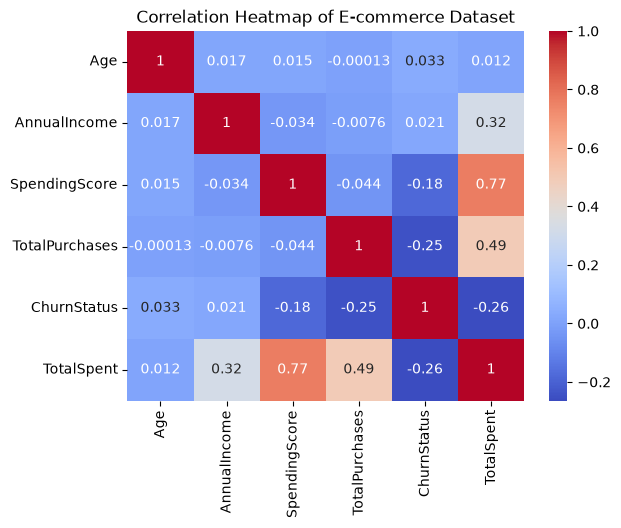

In [19]:
sns.heatmap(correlation, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap of E-commerce Dataset")

plt.show()

**Report:-**

Correlation Analysis — Findings

The correlation heatmap shows that SpendingScore has the strongest positive linear relationship with TotalSpent, with a correlation coefficient of approximately 0.77. TotalPurchases has a moderate positive correlation with TotalSpent (0.49), while AnnualIncome has a correlation of approximately 0.32.

Age has almost no linear correlation with TotalSpent in this dataset. ChurnStatus has negative correlations with TotalSpent (-0.26) and TotalPurchases (-0.25).

These findings help identify potential features for further analysis. However, correlation alone does not establish causation, and the relationships must be investigated further before selecting the final model features.

# 5.7 Outlier Analysis
A box plot helps identify potential outliers using the interquartile range (IQR). Points outside the whiskers are potential outliers, not necessarily errors.

c:\ProgramData\anaconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


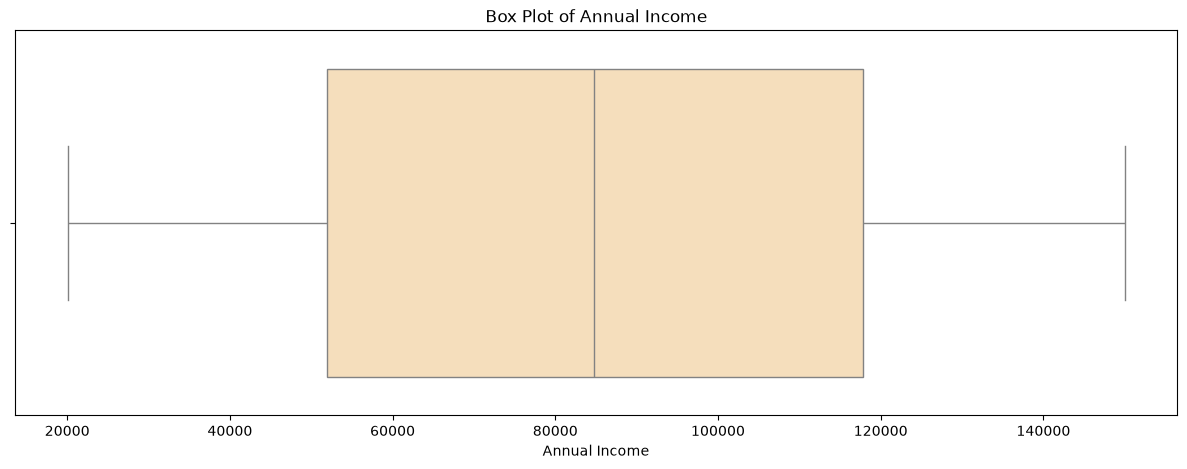

In [20]:
# Box plot for AnnualIncome

plt.figure(figsize=(15, 5))

sns.boxplot(x=df["AnnualIncome"],color="#FFE0B2")

plt.title("Box Plot of Annual Income")
plt.xlabel("Annual Income")

plt.show()

In [21]:
# Check outliers in AnnualIncome using IQR

Q1 = df["AnnualIncome"].quantile(0.25)
Q3 = df["AnnualIncome"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

outliers = df[
    (df["AnnualIncome"] < lower_limit) |
    (df["AnnualIncome"] > upper_limit)
]

print("Number of AnnualIncome outliers:", len(outliers))

Q1: 51945.5
Q3: 117858.0
IQR: 65912.5
Lower limit: -46923.25
Upper limit: 216726.75
Number of AnnualIncome outliers: 0


c:\ProgramData\anaconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


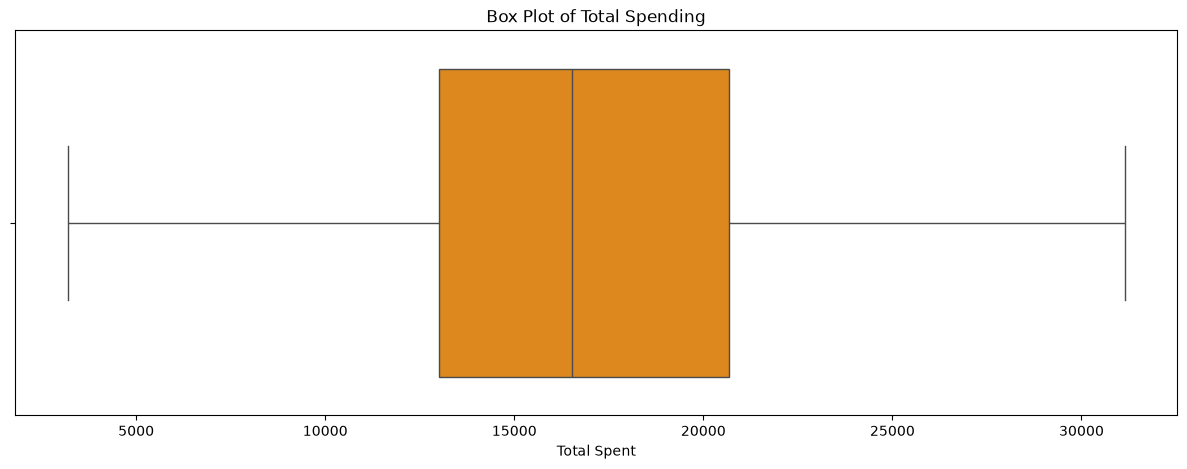

In [22]:
# Box plot for TotalSpent

plt.figure(figsize=(15, 5))

sns.boxplot(x=df["TotalSpent"],color="#FB8C00")

plt.title("Box Plot of Total Spending")
plt.xlabel("Total Spent")

plt.show()

In [23]:
# Check outliers in TotalSpent using IQR

Q1 = df["TotalSpent"].quantile(0.25)
Q3 = df["TotalSpent"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

outliers = df[
    (df["TotalSpent"] < lower_limit) |
    (df["TotalSpent"] > upper_limit)
]

print("Number of TotalSpent outliers:", len(outliers))


Q1: 13011.698062797479
Q3: 20672.23480806577
IQR: 7660.536745268289
Lower limit: 1520.8929448950457
Upper limit: 32163.0399259682
Number of TotalSpent outliers: 0


In [24]:
# Check outliers in other numerical columns

columns = ["Age", "SpendingScore", "TotalPurchases"]

for column in columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print(column, "- Number of outliers:", len(outliers))


Age - Number of outliers: 0
SpendingScore - Number of outliers: 0
TotalPurchases - Number of outliers: 0


**Report:-**

The IQR method was applied to the numerical columns "Age", "AnnualIncome", "SpendingScore", "TotalPurchases", and "TotalSpent".

No outliers were detected in any of these columns using the 1.5 × IQR rule. Therefore, no outlier treatment is required based on this method.

# 6. Feature Selection

Feature selection was planned separately for regression, classification, and clustering based on each task's objective.

- Regression target: "TotalSpent"
- Classification target: "ChurnStatus"
- Clustering features: "Age", "AnnualIncome", "SpendingScore", and "TotalPurchases"

"CustomerID" will be excluded from model inputs because it is an identifier. "ItemsBought" will be handled separately for Association Rule Mining.

The selected features will be reviewed for potential data leakage and suitability before model training.

# **7. Regression Analysis** 

## 1. Objective

The objective of regression is to predict the total amount spent by a customer based on customer characteristics and purchasing behavior.

**Target variable**: "TotalSpent"

**Input features**: "Age", "AnnualIncome", "SpendingScore", and "TotalPurchases".

The "CustomerID" column is excluded because it is an identifier.

# 2. Select input features & target variable

In [25]:
X = df[["Age", "AnnualIncome", "SpendingScore", "TotalPurchases"]]

Y = df["TotalSpent"]

# 3. Split the dataset into training and testing sets

In [26]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.20,
    random_state=42
)

# **7.1 Linear Regression**

Linear Regression is a supervised machine learning algorithm used to predict a continuous numerical value. In this project, it will learn the relationship between customer features and TotalSpent.

# 7.1.1 Create and Train the model

In [27]:
lr_model=LinearRegression()

In [28]:
lr_model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ -2.37, 0.05,149.43,200.55]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Age','AnnualIncome','SpendingScore','TotalPurchases']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,171.8
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,4


# 7.1.2 Make predictions

In [29]:
Y_pred=lr_model.predict(X_test)


# 7.1.3 Evaluate the model

The model will be evaluated using:

- MAE: Average absolute prediction error.
- MSE: Average squared prediction error.
- RMSE: Square root of the mean squared error, expressed in the target's units.
- R² score: Measures how well the model explains variation in the target on the evaluated data. A higher score is generally better.

In [30]:
mae = mean_absolute_error(Y_test, Y_pred)

mse = mean_squared_error(Y_test, Y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(Y_test, Y_pred)

print("Linear Regression Results")
print("--------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Results
--------------------------
MAE: 403.0991606545286
MSE: 249102.57015189825
RMSE: 499.10176332276995
R2 Score: 0.9922258840869083


# 7.1.4 Linear Regression — Evaluation Report

The Linear Regression model achieved an MAE of approximately 403.10, an MSE of 249,102.57, an RMSE of 499.10, and an R² score of 0.9922 on the test dataset.

The R² score indicates that the model explains approximately 99.22% of the variation in TotalSpent for this test set. The MAE and RMSE provide measures of prediction error.

# 7.1.5 Compare actual and predicted spending visually

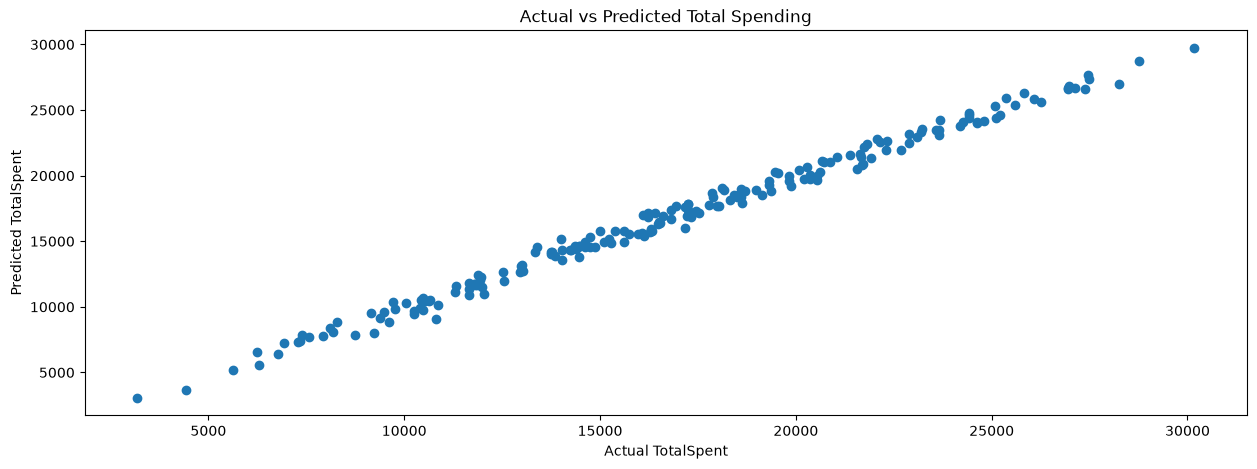

In [31]:
plt.figure(figsize=(15, 5))

plt.scatter(Y_test, Y_pred)

plt.title("Actual vs Predicted Total Spending")
plt.xlabel("Actual TotalSpent")
plt.ylabel("Predicted TotalSpent")

plt.show()

**Report:- Actual vs Predicted Total Spending**

The scatter plot shows a strong positive relationship between actual and predicted TotalSpent values. Most points follow a clear upward, nearly linear pattern, indicating that the Linear Regression model predicts customer spending closely on the test dataset.

This visual result is consistent with the high R² score of 0.9922. However, the model must be checked for potential target leakage and evaluated against other regression algorithms before selecting the final model.

## **7.2 Decision Tree Regression**

A Decision Tree Regressor predicts a continuous numerical value by splitting data into groups based on feature values. It can capture nonlinear relationships and will be compared with Linear Regression using the same training and testing sets.

# 7.2.1 Create and Train the model

In [32]:
dt_model=DecisionTreeRegressor(random_state=42)

In [33]:
dt_model.fit(X_train,Y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

# 7.2.2 Make predictions

In [34]:
dt_pred=dt_model.predict(X_test)

# 7.2.3 Evaluate the model

In [35]:
dt_mae = mean_absolute_error(Y_test, dt_pred)

dt_mse = mean_squared_error(Y_test, dt_pred)

dt_rmse = np.sqrt(dt_mse)

dt_r2 = r2_score(Y_test, dt_pred)

print("Decision Tree Regression Results")
print("--------------------------------")
print("MAE:", dt_mae)
print("MSE:", dt_mse)
print("RMSE:", dt_rmse)
print("R2 Score:", dt_r2)

Decision Tree Regression Results
--------------------------------
MAE: 1006.238157254636
MSE: 1677651.7497165937
RMSE: 1295.2419657023909
R2 Score: 0.9476430164644826


# 7.2.4 Decision Tree Regression — Evaluation Report

The Decision Tree Regressor achieved an MAE of approximately 1,006.24, an MSE of 1,677,651.75, an RMSE of 1,295.24, and an R² score of 0.9476 on the test dataset.

Compared with Linear Regression, the Decision Tree produced higher prediction errors and a lower R² score. Therefore, Linear Regression currently performs better on this test split.

Further comparison with other regression algorithms and investigation of possible target leakage are required before selecting the final model.


# **7.3 Random Forest Regressor**

Random Forest Regressor is an ensemble learning algorithm that combines predictions from multiple decision trees. It can capture nonlinear patterns and reduce the instability of an individual decision tree.

# 7.3.1 Create & Train the model

In [36]:
rf_model=RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [37]:
rf_model.fit(X_train,Y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

# 7.3.2 Make predictions

In [38]:
rf_pred=rf_model.predict(X_test)

# 7.3.3 Evaluate the model

In [39]:
rf_mae = mean_absolute_error(Y_test, rf_pred)
rf_mse = mean_squared_error(Y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(Y_test, rf_pred)

print("Random Forest Regression Results")
print("--------------------------------")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Regression Results
--------------------------------
MAE: 624.4440607140408
MSE: 644047.2853171905
RMSE: 802.525566768555
R2 Score: 0.9799002545557245


# 7.3.4 Random Forest Regression — Evaluation Report

The Random Forest Regressor achieved an MAE of approximately 624.44, an MSE of 644,047.29, an RMSE of 802.53, and an R² score of 0.9799 on the test dataset.

Compared with the Decision Tree Regressor, Random Forest achieved lower prediction errors and a higher R² score. However, Linear Regression currently performs best among the three models evaluated.

The final model selection will consider further diagnostics and potential target leakage before drawing conclusions about generalization performance.

# 7.4 Comparison of all evaluated models

In [40]:
regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        mae,
        dt_mae,
        rf_mae
    ],
    "MSE": [
        mse,
        dt_mse,
        rf_mse
    ],
    "RMSE": [
        rmse,
        dt_rmse,
        rf_rmse
    ],
    "R2 Score": [
        r2,
        dt_r2,
        rf_r2
    ]
})

regression_results


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,403.099161,2.491026e+05,499.101763,0.992226
1,Decision Tree,1006.238157,1.677652e+06,1295.241966,0.947643
2,Random Forest,624.444061,6.440473e+05,802.525567,0.979900


# 7.4.1 Regression Model Comparison — Report

Three regression algorithms were evaluated: Linear Regression, Decision Tree Regressor, and Random Forest Regressor.

Linear Regression achieved the lowest MAE (403.10), lowest MSE (249,102.57), lowest RMSE (499.10), and highest R² score (0.9922) among the three models.

Random Forest performed better than the Decision Tree, while Linear Regression achieved the best results on the current test split.

**Therefore, Linear Regression is the best-performing model in the initial comparison. However, this result is provisional until potential target leakage is investigated and the model's generalization performance is assessed.**

# 7.5 Save regression results to a CSV file

In [41]:
regression_results.to_csv(
    "regression_model_comparison.csv",
    index=False
)

print("Regression results saved successfully!")

Regression results saved successfully!


## **8. Classification**

## 1. Objective

The objective is to classify customers according to their churn status.

**Target variable**: "ChurnStatus"

**Input features**: "Age", "AnnualIncome", "SpendingScore", "TotalPurchases", and "TotalSpent".

# 2. Select input features & target variable

In [42]:
X_class = df[
    [
        "Age",
        "AnnualIncome",
        "SpendingScore",
        "TotalPurchases",
        "TotalSpent"
    ]
]


Y_class = df["ChurnStatus"]

# 3. Split the dataset into training and testing data

In [43]:
X_train_class,X_test_class,Y_train_class,Y_test_class=train_test_split(
    X_class,Y_class,test_size=0.20,random_state=42,stratify=Y_class
)

# 8.1 Logistic Regression Classification

Logistic Regression estimates the probability that a record belongs to a particular class. In this project, it will be used to classify customers according to their churn status.

# 8.1.1 Create Pipeline for model creating & training

In [44]:
lr_class_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(random_state=42))
])

lr_class_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elas

In [45]:
lr_class_model.fit(X_train_class, Y_train_class)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Age','AnnualIncome','SpendingScore','TotalPurchases','TotalSpent']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


# 8.1.2 Make predictions

In [46]:
Y_class_pred = lr_class_model.predict(X_test_class)

# 8.1.3 Evaluate the model

In [47]:
accuracy = accuracy_score(Y_test_class,Y_class_pred)

print("Logistic Regression Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(
    Y_test_class,
    Y_class_pred,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(Y_test_class, Y_class_pred))

Logistic Regression Accuracy: 0.99

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       196
           1       1.00      0.50      0.67         4

    accuracy                           0.99       200
   macro avg       0.99      0.75      0.83       200
weighted avg       0.99      0.99      0.99       200


Confusion Matrix:
[[196   0]
 [  2   2]]


# 8.1.4 Visualize the confusion matrix

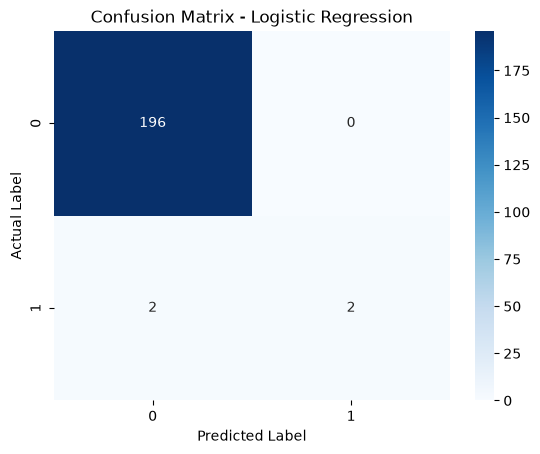

In [48]:
cm = confusion_matrix(Y_test_class, Y_class_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

# 8.1.5 Logistic Regression — Classification Report

The Logistic Regression classifier achieved 99% accuracy on the test dataset. For class 1, the precision was 1.00, recall was 0.50, and F1-score was approximately 0.67.

The confusion matrix shows 196 true negatives, zero false positives, two false negatives, and two true positives.

Although the overall accuracy is high, the model identified only two of the four churn-positive customers in the test set. This highlights the impact of class imbalance.

Only four positive examples are present in the test set, so these results are unstable and should be interpreted cautiously. Additional evaluation and comparison with other classifiers are necessary.


# **8.2 Decision Tree Classifier**

A Decision Tree Classifier is a supervised machine learning algorithm that predicts a class by learning decision rules from input features. In this project, it will classify customers according to their churn status.

The model will be evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. Because the churn classes are imbalanced, recall and F1-score for class 1 are particularly important.

# 8.2.1 Create & train the model

In [49]:
dt_class_model = DecisionTreeClassifier(random_state=42)

In [50]:
dt_class_model.fit(X_train_class,Y_train_class)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

# 8.2.2 Make predictions

In [51]:
dt_class_pred=dt_class_model.predict(X_test_class)

# 8.2.3 Evaluate the model

In [52]:
dt_class_accuracy = accuracy_score(
    Y_test_class,
    dt_class_pred
)

print("Decision Tree Accuracy:", dt_class_accuracy)

print("\nClassification Report:")

print(classification_report(
    Y_test_class,
    dt_class_pred,
    zero_division=0
))

print("\nConfusion Matrix:")

print(confusion_matrix(
    Y_test_class,
    dt_class_pred
))


Decision Tree Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       196
           1       1.00      1.00      1.00         4

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200


Confusion Matrix:
[[196   0]
 [  0   4]]


# 8.2.4 Visualize the confusion matrix

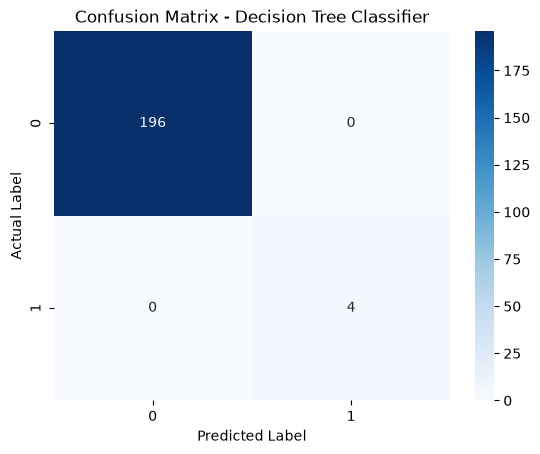

In [53]:
dt_cm = confusion_matrix(
    Y_test_class,
    dt_class_pred
)

sns.heatmap(dt_cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix - Decision Tree Classifier")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

# 8.2.5 Decision Tree Classifier — Evaluation Report

The Decision Tree Classifier achieved 100% accuracy on the test dataset. Precision, recall, and F1-score were all 1.00 for both classes.

The confusion matrix contained 196 true negatives, zero false positives, zero false negatives, and four true positives.

# **8.3 Random Forest Classifier**

Random Forest is an ensemble learning algorithm that combines multiple decision trees to make a classification prediction. It can capture nonlinear relationships and may generalize better than an individual decision tree.

The model will be evaluated using accuracy, precision, recall, F1-score, and a confusion matrix, with special attention to the minority churn class.

# 8.3.1 Create & train the model

In [54]:
rf_class_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [55]:
rf_class_model.fit(X_train_class, Y_train_class)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

# 8.3.2 Make predictions

In [56]:
rf_class_pred = rf_class_model.predict(X_test_class)


# 8.3.3 Evaluate the model

In [57]:
rf_class_accuracy = accuracy_score(
    Y_test_class,
    rf_class_pred
)

print("Random Forest Accuracy:", rf_class_accuracy)

print("\nClassification Report:")

print(classification_report(
    Y_test_class,
    rf_class_pred,
    zero_division=0
))

print("\nConfusion Matrix:")

print(confusion_matrix(
    Y_test_class,
    rf_class_pred
))

Random Forest Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       196
           1       1.00      1.00      1.00         4

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200


Confusion Matrix:
[[196   0]
 [  0   4]]


# 8.3.4 Visualize the confusion matrix

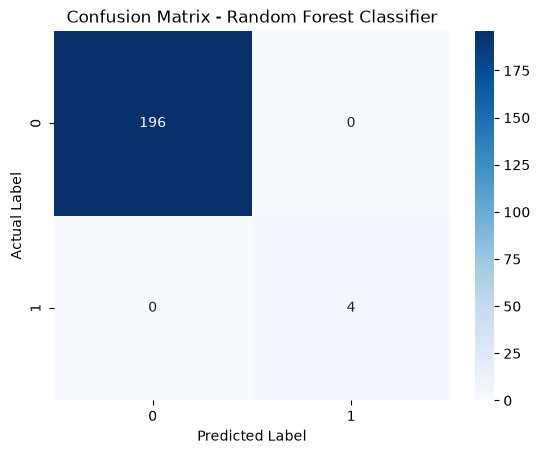

In [58]:
rf_cm = confusion_matrix(
    Y_test_class,
    rf_class_pred
)

sns.heatmap(rf_cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix - Random Forest Classifier")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()


# 8.3.5 Random Forest Classifier — Evaluation Report

The Random Forest Classifier achieved 100% accuracy on the test dataset. Precision, recall, and F1-score were 1.00 for both classes.

The confusion matrix contained 196 true negatives, zero false positives, zero false negatives, and four true positives.

# 8.4 Comparison all three classification models

In [59]:
classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        dt_class_accuracy,
        rf_class_accuracy
    ],
    "Churn Precision": [
        classification_report(
            Y_test_class, Y_class_pred,
            output_dict=True, zero_division=0
        )["1"]["precision"],
        classification_report(
            Y_test_class, dt_class_pred,
            output_dict=True, zero_division=0
        )["1"]["precision"],
        classification_report(
            Y_test_class, rf_class_pred,
            output_dict=True, zero_division=0
        )["1"]["precision"]
    ],
    "Churn Recall": [
        classification_report(
            Y_test_class, Y_class_pred,
            output_dict=True, zero_division=0
        )["1"]["recall"],
        classification_report(
            Y_test_class, dt_class_pred,
            output_dict=True, zero_division=0
        )["1"]["recall"],
        classification_report(
            Y_test_class, rf_class_pred,
            output_dict=True, zero_division=0
        )["1"]["recall"]
    ],
    "Churn F1 Score": [
        classification_report(
            Y_test_class, Y_class_pred,
            output_dict=True, zero_division=0
        )["1"]["f1-score"],
        classification_report(
            Y_test_class, dt_class_pred,
            output_dict=True, zero_division=0
        )["1"]["f1-score"],
        classification_report(
            Y_test_class, rf_class_pred,
            output_dict=True, zero_division=0
        )["1"]["f1-score"]
    ]
})

classification_results

,Model,Accuracy,Churn Precision,Churn Recall,Churn F1 Score
0,Logistic Regression,0.99,1.0,0.5,0.666667
1,Decision Tree,1.00,1.0,1.0,1.000000
2,Random Forest,1.00,1.0,1.0,1.000000


# 8.5 Save the comparison table

In [60]:
classification_results.to_csv(
    "classification_model_comparison.csv",
    index=False
)

# **9. Clustering**

# 1. Objective

The objective is to group customers with similar characteristics using unsupervised machine learning.

K-Means clustering will be applied to Age, AnnualIncome, SpendingScore, and TotalPurchases.

CustomerID will be excluded because it is an identifier. ChurnStatus will not be used to form the clusters because clustering should discover groups without relying on existing class labels.

The resulting clusters will be analyzed to understand customer characteristics and potential business opportunities.


# 2. Select input features

In [61]:
X_cluster = df[
    [
        "Age",
        "AnnualIncome",
        "SpendingScore",
        "TotalPurchases"
    ]
]

# 3. Standardize the clustering features

In [62]:
scaler_cluster = StandardScaler()

X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

# 9.1 K-Means

K-Means is an unsupervised machine learning algorithm that groups similar data points into clusters.

In this project, K-Means will group customers based on their age, annual income, spending score, and purchase count.

We will initially use three clusters to explore possible customer segments.

# 9.1.1 Create & train the model 

In [63]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

In [64]:
kmeans.fit(X_cluster_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 4)","[[ 0.

# 9.1.2 Assign cluster

In [65]:
df["Cluster"]=kmeans.predict(X_cluster_scaled)

In [66]:
df.head()

,CustomerID,Age,AnnualIncome,SpendingScore,TotalPurchases,ChurnStatus,TotalSpent,ItemsBought,Cluster
0,CUST_1000,56,125186,58,13,0,16247.405882,Charger,0
1,CUST_1001,69,54674,67,49,0,21973.364975,"T-Shirt,Shoes,Phone",2
2,CUST_1002,46,55854,56,41,0,19399.861629,Smartwatch,2
3,CUST_1003,32,66271,40,17,0,12791.643911,"Smartwatch,Cover,Phone,Mouse",1
4,CUST_1004,60,93688,98,9,0,21285.349780,"Cover,Keyboard,Charger,Phone",0


# 9.1.3 Visualize the clusters

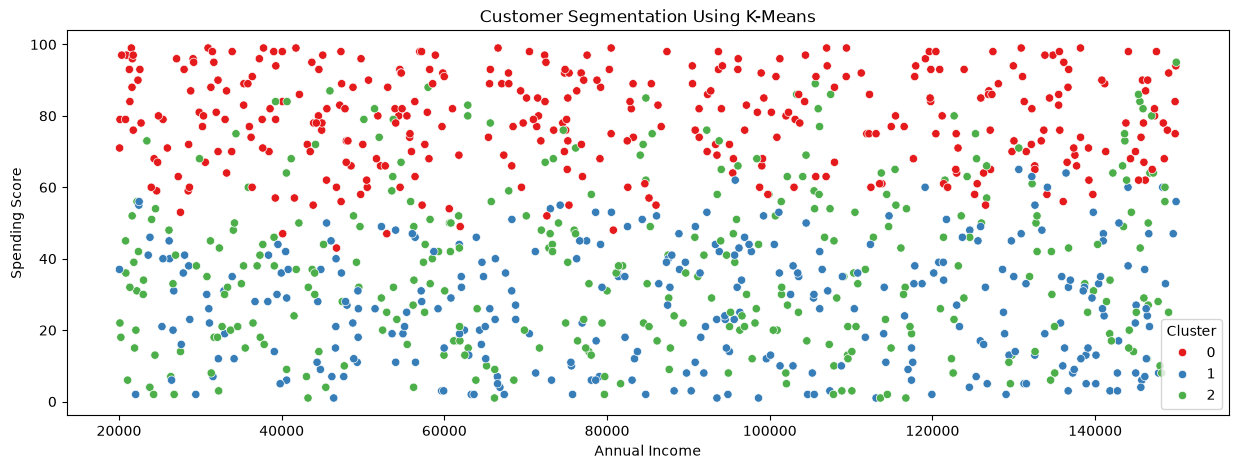

In [67]:
plt.figure(figsize=(15, 5))

sns.scatterplot(
    x=df["AnnualIncome"],
    y=df["SpendingScore"],
    hue=df["Cluster"],
    palette="Set1"
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")

plt.show()

**Report:-** This chart shows customer groups using annual income and spending score.

# 9.1.4 Anaylze the clusters

In [68]:
cluster_summary = df.groupby("Cluster")[
    ["Age", "AnnualIncome", "SpendingScore", "TotalPurchases"]
].mean()

cluster_summary

,Age,AnnualIncome,SpendingScore,TotalPurchases
Cluster,,,,
0,45.490085,81678.025496,79.161473,21.087819
1,42.194175,89681.559871,26.847896,14.485437
2,43.559172,83911.334320,37.940828,40.399408


# 9.1.5 K-Means Clustering — Results and Interpretation

K-Means clustering was applied to Age, AnnualIncome, SpendingScore, and TotalPurchases after feature standardization. Three clusters were created for initial customer segmentation.

Cluster 0 has the highest average SpendingScore (79.16), indicating a high-spending group. Cluster 1 has the highest average AnnualIncome (89,681.56) but the lowest average SpendingScore (26.85). Cluster 2 has the highest average TotalPurchases (40.40), suggesting frequent purchasing activity.

These groups may support different marketing strategies, such as loyalty rewards, targeted promotions, and repeat-purchase campaigns. These interpretations are exploratory and should be validated against additional customer and business information.

Three clusters were selected as an initial choice for this analysis; the optimal number of clusters has not been established.


# **10. Association Rule mining**

# 1. Objective

Association Rule Mining identifies products that frequently occur together in customer transactions. This can help businesses discover product combinations for recommendations, cross-selling, and product bundling.

The ItemsBought column contains comma-separated product names. We will convert these transactions into a one-hot encoded format and apply the Apriori algorithm to discover frequent itemsets and association rules.

# 2. Split ItemsBought into individual products

In [69]:
df["ItemsBought_Split"] = df["ItemsBought"].str.split(",")

# Display the original and split columns

df[["ItemsBought", "ItemsBought_Split"]].head(10)

,ItemsBought,ItemsBought_Split
0,Charger,[Charger]
1,"T-Shirt,Shoes,Phone","[T-Shirt, Shoes, Phone]"
2,Smartwatch,[Smartwatch]
3,"Smartwatch,Cover,Phone,Mouse","[Smartwatch, Cover, Phone, Mouse]"
4,"Cover,Keyboard,Charger,Phone","[Cover, Keyboard, Charger, Phone]"
5,"T-Shirt,Mouse","[T-Shirt, Mouse]"
6,"Keyboard,Phone,Headphones","[Keyboard, Phone, Headphones]"
7,"Shoes,Charger,Headphones","[Shoes, Charger, Headphones]"
8,Laptop,[Laptop]
9,"Headphones,Phone,T-Shirt","[Headphones, Phone, T-Shirt]"


# 10.1 Apriori Algorithm

# 10.1.1 Convert lists into transaction format 

In [70]:
te = TransactionEncoder()

transaction_array = te.fit(
    df["ItemsBought_Split"]
).transform(df["ItemsBought_Split"])

basket = pd.DataFrame(
    transaction_array,
    columns=te.columns_
)

# Display the transaction table

basket.head(10)

,Charger,Cover,Headphones,Keyboard,Laptop,Mouse,Phone,Shoes,Smartwatch,T-Shirt
0,True,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,True,True,False,True
2,False,False,False,False,False,False,False,False,True,False
3,False,True,False,False,False,True,True,False,True,False
4,True,True,False,True,False,False,True,False,False,False
5,False,False,False,False,False,True,False,False,False,True
6,False,False,True,True,False,False,True,False,False,False
7,True,False,True,False,False,False,False,True,False,False
8,False,False,False,False,True,False,False,False,False,False
9,False,False,True,False,False,False,True,False,False,True


# 10.2 Find frequent product combinations

In [71]:
frequent_itemsets = apriori(
    basket,
    min_support=0.02,
    use_colnames=True
)

frequent_itemsets.sort_values(
    by="support",
    ascending=False
)

,support,itemsets
6,0.273,(Phone)
3,0.266,(Keyboard)
1,0.264,(Cover)
7,0.257,(Shoes)
2,0.251,(Headphones)
8,0.250,(Smartwatch)
9,0.250,(T-Shirt)
0,0.241,(Charger)
4,0.241,(Laptop)
5,0.239,(Mouse)


# 10.3 Generate Association Rules

We will evaluate the rules using support, confidence and lift. These metrics help identify product combinations that may be useful for cross selling  and product recommendations.

In [72]:
# Generate association rules

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.20
)

# Select important columns and sort by lift

rules = rules[
    [
        "antecedents",
        "consequents",
        "support",
        "confidence",
        "lift"
    ]
].sort_values(
    by="lift",
    ascending=False
)

# Display the top 10 rules

rules.head(10)


,antecedents,consequents,support,confidence,lift
76,"(Laptop, T-Shirt)",(Headphones),0.020,0.344828,1.373815
75,"(Headphones, T-Shirt)",(Laptop),0.020,0.327869,1.360452
71,"(Cover, Shoes)",(Smartwatch),0.021,0.333333,1.333333
73,"(Smartwatch, Shoes)",(Cover),0.021,0.338710,1.282991
72,"(Cover, Smartwatch)",(Shoes),0.021,0.313433,1.219583
74,"(Headphones, Laptop)",(T-Shirt),0.020,0.303030,1.212121
28,(Laptop),(Headphones),0.066,0.273859,1.091071
27,(Headphones),(Laptop),0.066,0.262948,1.091071
22,(Smartwatch),(Cover),0.067,0.268000,1.015152
21,(Cover),(Smartwatch),0.067,0.253788,1.015152


# 10.4 Association Rule Mining — Results and Interpretation

The Apriori algorithm was applied to the ItemsBought column after splitting product names and converting transactions into one-hot encoded data.

Frequent itemsets were identified using a minimum support threshold of 0.02, and association rules were generated using a minimum confidence threshold of 0.20.

Among the displayed rules, Laptop and T-Shirt predicting Headphones had a support of 0.020, confidence of approximately 0.3448, and lift of approximately 1.3738. This indicates a positive association between these product combinations in the dataset.

Other positive associations were found among Shoes, Cover, and Smartwatch. These relationships may provide ideas for product bundling and cross-selling strategies.

Association rules identify co-occurrence patterns, not causation. The findings should be validated on additional transactions before being used to make business decisions.


# 10.5 Save the association rules

In [73]:
rules.to_csv(
    "association_rules.csv",
    index=False
)

# 11. Save clean csv file

In [79]:
df.to_csv(
    "ecommerce_customer_analytics_clean.csv",
    index=False
)

# 12. Final Conclusion

**Project Summary**

This project explored an e-commerce customer dataset using four machine learning approaches: regression, classification, clustering, and association rule mining.

1. Regression

Linear Regression achieved the best initial results among the three evaluated regression models, with an MAE of 403.10, RMSE of 499.10, and R² score of 0.9922. 

2. Classification

Logistic Regression achieved 99% accuracy but identified only 50% of the churn-positive customers in the test set. Decision Tree and Random Forest achieved 100% accuracy on the current test split. 

The assumed interpretation of ChurnStatus is 1 = churned and 0 = active. This assumption must be verified against the dataset documentation.

3. Clustering

K-Means grouped customers into three initial segments based on age, annual income, spending score, and total purchases. The resulting groups showed differences in spending scores, income, and purchase frequency that could help guide customer segmentation strategies.

4. Association Rule Mining

The Apriori algorithm identified product combinations with positive associations, including Laptop and T-Shirt associated with Headphones. These patterns may support cross-selling ideas, but association does not imply causation.

**Business Recommendations**

- Investigate customers with low spending scores and test targeted promotional campaigns.
- Explore loyalty rewards for customers with frequent purchases.
- Evaluate product bundles using the strongest association rules.
- Investigate customer churn patterns and validate the classification models before using predictions for customer retention decisions.

**Limitations**

- The churn-positive class contains relatively few records.
- Classification metrics may be unstable because the test set contains only four positive examples.
- The reason for the unusually high regression score must be investigated.
- Three clusters were selected as an initial choice rather than established as optimal.
- Association rules depend on the dataset, transaction frequency, and chosen thresholds.
- Model performance on this dataset may not represent performance on new customers.

**Future Scope**

- Obtain additional labeled customer records, particularly churn-positive examples.
- Validate the models using appropriate cross-validation and unseen data.
- Investigate feature relationships and potential target leakage.
- Explore alternative classification models and class-imbalance handling.
- Test whether customer segments and product associations remain consistent on new data.

**Final Note**

The project demonstrates the application of supervised and unsupervised machine learning techniques to customer analytics.